<a href="https://colab.research.google.com/github/MandeGanesh778/ds-experiments/blob/main/exp8abcde.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
html_content = """
<html>
<body>

<div class="review">
    <h3 class="review-title">Excellent Product</h3>
    <p class="review-text">The product quality is very good.</p>
    <span class="rating">5/5</span>
</div>

<div class="review">
    <h3 class="review-title">Good Value</h3>
    <p class="review-text">Good product at an affordable price.</p>
    <span class="rating">4/5</span>
</div>

<div class="review">
    <h3 class="review-title">Average Experience</h3>
    <p class="review-text">The product is okay but could be better.</p>
    <span class="rating">3/5</span>
</div>

</body>
</html>
"""

with open("reviews.html", "w", encoding="utf-8") as file:
    file.write(html_content)

print("reviews.html created successfully!")
from bs4 import BeautifulSoup
import pandas as pd
with open("reviews.html", "r", encoding="utf-8") as file:
    html_content = file.read()

soup = BeautifulSoup(html_content, "html.parser")
review_blocks = soup.select(".review")
records = []
for block in review_blocks:
    review_element = block.select_one(".review-text")
    rating_element = block.select_one(".rating")
    title_element = block.select_one(".review-title")
    review_text = review_element.get_text(strip=True) if review_element else ""
    rating = rating_element.get_text(strip=True) if rating_element else ""
    title = title_element.get_text(strip=True) if title_element else ""
    if review_text:
        records.append({
            "title": title,
            "review": review_text,
            "rating": rating
        })

df = pd.DataFrame(records)
display(df)
df.to_csv("product_reviews.csv", index=False, encoding="utf-8-sig")
print("Total reviews extracted:", len(df))
print("Saved to product_reviews.csv")


reviews.html created successfully!


,title,review,rating
0,Excellent Product,The product quality is very good.,5/5
1,Good Value,Good product at an affordable price.,4/5
2,Average Experience,The product is okay but could be better.,3/5


Total reviews extracted: 3
Saved to product_reviews.csv


Dataset created successfully!
                                           review
0           This product is excellent and amazing
1          I love this product, very good quality
2  The delivery was fast and the product is great
3              Amazing quality, worth every penny
4                     Very happy with my purchase
Total reviews: 30


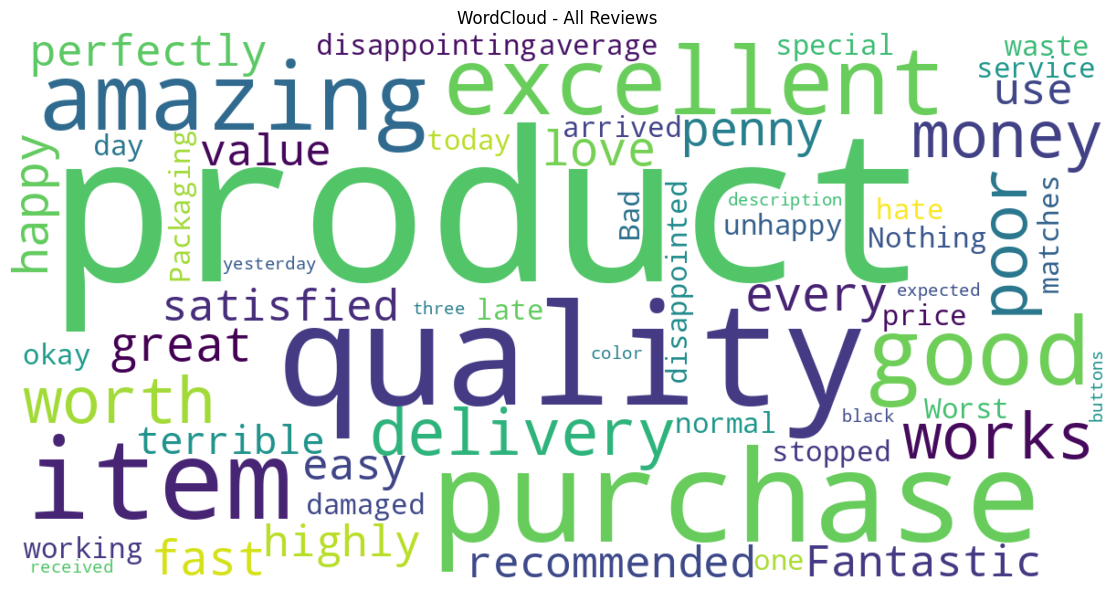

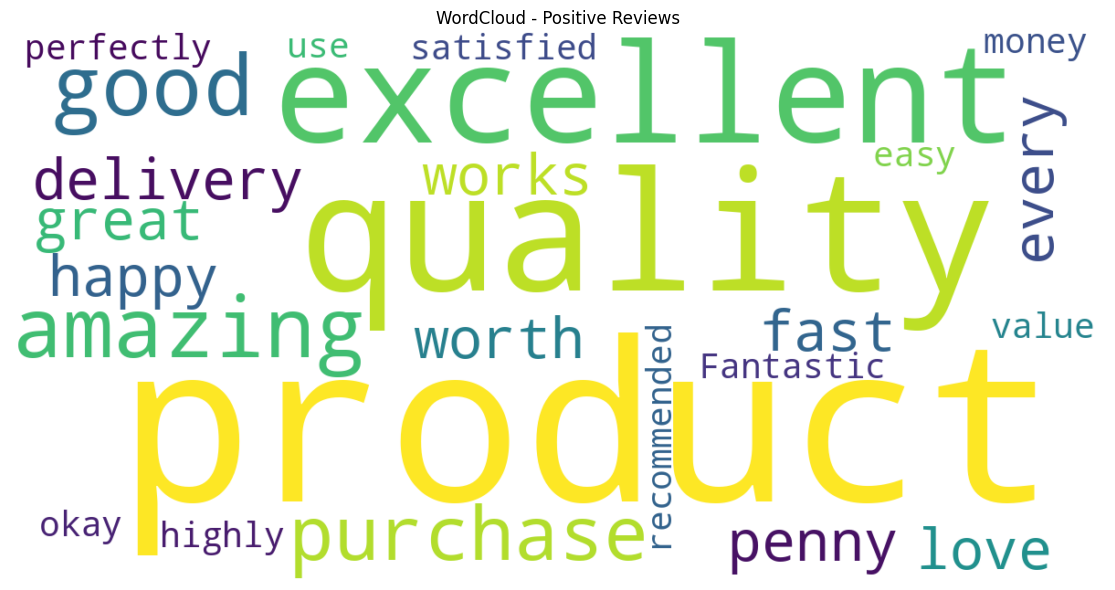

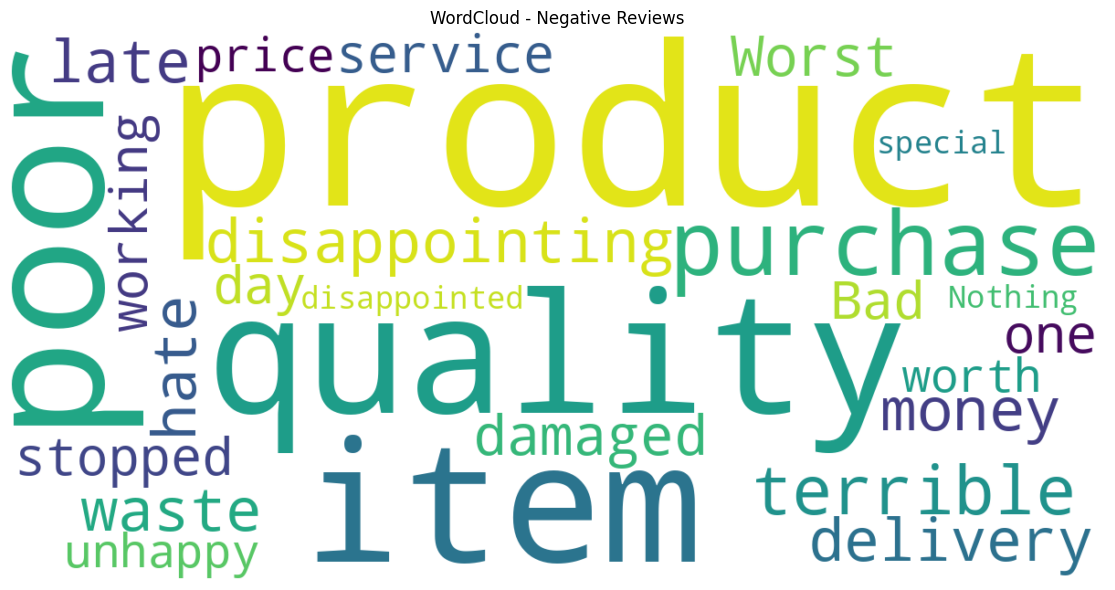

sentiment
Positive    11
Negative    11
Neutral      8
Name: count, dtype: int64
WordCloud images saved successfully.


In [20]:
import pandas as pd

data = {
    "review": [
        "This product is excellent and amazing",
        "I love this product, very good quality",
        "The delivery was fast and the product is great",
        "Amazing quality, worth every penny",
        "Very happy with my purchase",
        "The product works perfectly",
        "Excellent value for money",
        "Good quality and easy to use",
        "I am satisfied with this purchase",
        "Fantastic product, highly recommended",
        "The product is terrible and disappointing",
        "Very poor quality, waste of money",
        "I hate this product",
        "The delivery was late and the item was damaged",
        "Worst purchase ever",
        "The product stopped working after one day",
        "Bad quality and poor service",
        "I am unhappy with this product",
        "Not worth the price",
        "Very disappointed with the purchase",
        "The product is okay",
        "It is an average product",
        "Nothing special about this item",
        "The product arrived today",
        "Packaging was normal",
        "The item matches the description",
        "It works as expected",
        "I received the product yesterday",
        "The color is black",
        "The product has three buttons"
    ]
}
df = pd.DataFrame(data)
df.to_csv("product_reviews.csv", index=False)
print("Dataset created successfully!")
print(df.head())
print("Total reviews:", len(df))

import matplotlib.pyplot as plt
from wordcloud import WordCloud
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)
analyzer = SentimentIntensityAnalyzer()
def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"
df["sentiment"] = df["review"].apply(classify_sentiment)
def generate_wordcloud(text, title, filename):
    if not text.strip():
        print(f"No text available for: {title}")
        return

    cloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=150,
        collocations=False
    ).generate(text)
    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
all_text = " ".join(df["review"])
generate_wordcloud(
    all_text, "WordCloud - All Reviews", "wordcloud_all.png"
)
positive_text = " ".join(
    df.loc[df["sentiment"] == "Positive", "review"]
)
generate_wordcloud(
    positive_text, "WordCloud - Positive Reviews",
    "wordcloud_positive.png"
)
negative_text = " ".join(
    df.loc[df["sentiment"] == "Negative", "review"]
)
generate_wordcloud(
    negative_text, "WordCloud - Negative Reviews",
    "wordcloud_negative.png"
)
df.to_csv("product_reviews_analyzed.csv", index=False)
print(df["sentiment"].value_counts())
print("WordCloud images saved successfully.")

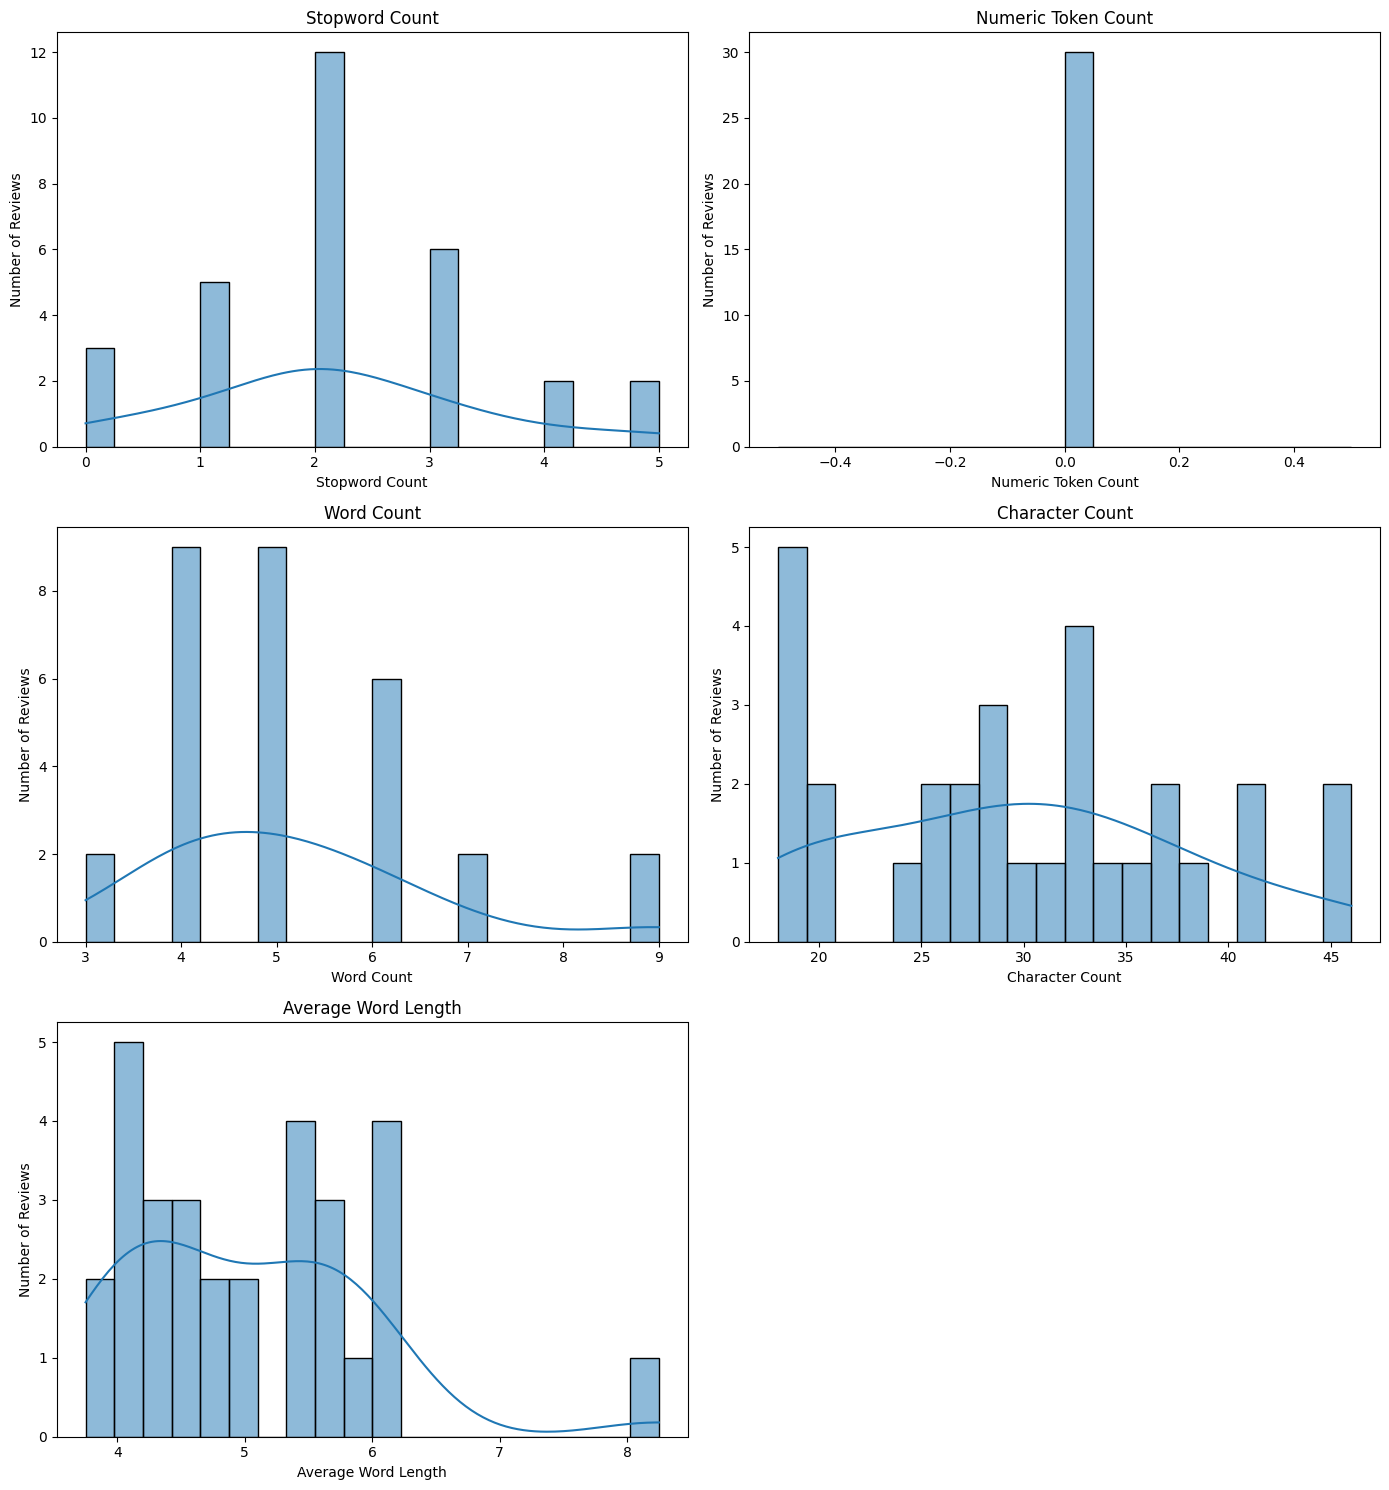

Top 10 stopwords:
[('the', 16), ('this', 6), ('is', 6), ('and', 6), ('i', 5), ('very', 4), ('was', 4), ('with', 4), ('am', 2), ('it', 2)]

Descriptive statistics:
       stopword_count  numeric_count  word_count  character_count  \
count       30.000000           30.0   30.000000        30.000000   
mean         2.166667            0.0    5.166667        29.766667   
std          1.288767            0.0    1.464131         8.143893   
min          0.000000            0.0    3.000000        18.000000   
25%          1.250000            0.0    4.000000        24.250000   
50%          2.000000            0.0    5.000000        29.500000   
75%          3.000000            0.0    6.000000        34.750000   
max          5.000000            0.0    9.000000        46.000000   

       average_word_length  
count            30.000000  
mean              5.009656  
std               0.980030  
min               3.750000  
25%               4.222222  
50%               4.900000  
75%         

In [21]:
import re
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from collections import Counter

nltk.download("stopwords", quiet=True)

df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

stop_words = set(stopwords.words("english"))

def analyze_review(text):
    tokens = re.findall(r"\b[\w']+\b", text.lower())
    words = re.findall(r"\b[A-Za-z]+\b", text)
    numeric_tokens = re.findall(r"\b\d+(?:\.\d+)?\b", text)

    stopword_tokens = [
        token for token in tokens if token in stop_words
    ]

    return pd.Series({
        "word_count": len(tokens),
        "character_count": len(text),
        "numeric_count": len(numeric_tokens),
        "stopword_count": len(stopword_tokens),
        "average_word_length": (
            sum(len(word) for word in words) / len(words)
            if words else 0
        )
    })

statistics = df["review"].apply(analyze_review)
df = pd.concat([df, statistics], axis=1)

df.to_csv("review_statistics.csv", index=False)
columns = [
    ("stopword_count", "Stopword Count"),
    ("numeric_count", "Numeric Token Count"),
    ("word_count", "Word Count"),
    ("character_count", "Character Count"),
    ("average_word_length", "Average Word Length")
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, (column, title) in enumerate(columns):
    sns.histplot(
        data=df, x=column, kde=True,
        ax=axes[i], bins=20
    )
    axes[i].set_title(title)
    axes[i].set_xlabel(title)
    axes[i].set_ylabel("Number of Reviews")
axes[-1].axis("off")
plt.tight_layout()
plt.savefig("review_statistics_distributions.png", dpi=300)
plt.show()
all_tokens = re.findall(
    r"\b[\w']+\b",
    " ".join(df["review"]).lower()
)
stopword_frequency = Counter(
    token for token in all_tokens if token in stop_words
)
print("Top 10 stopwords:")
print(stopword_frequency.most_common(10))

print("\nDescriptive statistics:")
print(df[[
    "stopword_count",
    "numeric_count",
    "word_count",
    "character_count",
    "average_word_length"
]].describe())

In [22]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer as NLTKVADER
from vaderSentiment.vaderSentiment import (
    SentimentIntensityAnalyzer as StandaloneVADER
)

# Download VADER lexicon for NLTK
nltk.download("vader_lexicon", quiet=True)

df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

# Initialize both implementations
nltk_analyzer = NLTKVADER()
vader_analyzer = StandaloneVADER()

def classify(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

# NLTK VADER scores
nltk_scores = df["review"].apply(
    nltk_analyzer.polarity_scores
)

df["nltk_positive"] = nltk_scores.apply(lambda x: x["pos"])
df["nltk_negative"] = nltk_scores.apply(lambda x: x["neg"])
df["nltk_neutral"] = nltk_scores.apply(lambda x: x["neu"])
df["nltk_compound"] = nltk_scores.apply(lambda x: x["compound"])
vader_scores = df["review"].apply(
    vader_analyzer.polarity_scores
)
df["vader_positive"] = vader_scores.apply(lambda x: x["pos"])
df["vader_negative"] = vader_scores.apply(lambda x: x["neg"])
df["vader_neutral"] = vader_scores.apply(lambda x: x["neu"])
df["vader_compound"] = vader_scores.apply(lambda x: x["compound"])
df["nltk_sentiment"] = df["nltk_compound"].apply(classify)
df["vader_sentiment"] = df["vader_compound"].apply(classify)
print(df[[
    "review",
    "nltk_compound",
    "nltk_sentiment",
    "vader_compound",
    "vader_sentiment"
]].head(10).to_string(index=False))
print("\nNLTK sentiment distribution:")
print(df["nltk_sentiment"].value_counts())
print("\nStandalone VADER sentiment distribution:")
print(df["vader_sentiment"].value_counts())
df.to_csv("sentiment_analysis_results.csv", index=False)
print("\nResults saved to sentiment_analysis_results.csv")

                                        review  nltk_compound nltk_sentiment  vader_compound vader_sentiment
         This product is excellent and amazing         0.8176       Positive          0.8176        Positive
        I love this product, very good quality         0.8122       Positive          0.8122        Positive
The delivery was fast and the product is great         0.6249       Positive          0.6249        Positive
            Amazing quality, worth every penny         0.6908       Positive          0.6908        Positive
                   Very happy with my purchase         0.6115       Positive          0.6115        Positive
                   The product works perfectly         0.6369       Positive          0.6369        Positive
                     Excellent value for money         0.7269       Positive          0.7269        Positive
                  Good quality and easy to use         0.7003       Positive          0.7003        Positive
             I am s

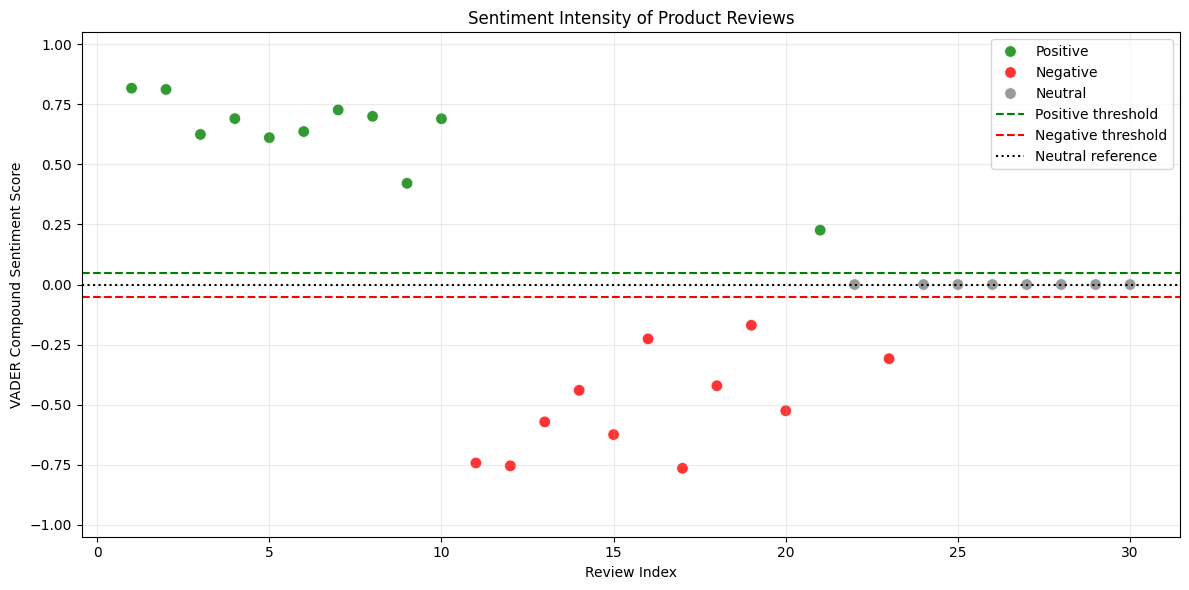

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("sentiment_analysis_results.csv")
df["vader_compound"] = pd.to_numeric(
    df["vader_compound"], errors="coerce"
)
df = df.dropna(subset=["vader_compound"]).reset_index(drop=True)
df["review_index"] = range(1, len(df) + 1)
palette = {
    "Positive": "green",
    "Negative": "red",
    "Neutral": "gray"
}
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="review_index",
    y="vader_compound",
    hue="vader_sentiment",
    palette=palette,
    s=70,
    alpha=0.8
)

plt.axhline(
    y=0.05, color="green", linestyle="--",
    label="Positive threshold"
)

plt.axhline(
    y=-0.05, color="red", linestyle="--",
    label="Negative threshold"
)

plt.axhline(
    y=0.0, color="black", linestyle=":",
    label="Neutral reference"
)

plt.ylim(-1.05, 1.05)
plt.xlabel("Review Index")
plt.ylabel("VADER Compound Sentiment Score")
plt.title("Sentiment Intensity of Product Reviews")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()